# 02. Zero-shot 변이 효과 예측 — masked marginal (ESM-2, ProteinGym)

**등급**: 🟢 Mac 로컬 (MPS/CPU) · **예상 시간**: 10~20분 (650M 포함) · **다운로드**: ESM-2 8M·35M·150M·650M(합계 약 3.4 GB), ProteinGym v1.3 치환 데이터(43 MB)
650M이 부담스러우면 `MODELS`에서 빼도 된다.

**질문**: 라벨(DMS 점수)을 전혀 쓰지 않고, 사전학습된 ESM-2의 확률만으로 변이 효과를 얼마나 순위 지을 수 있는가? 모델이 커지면 좋아지는가? assay 유형에 따라 다른가?

**방법**: 모듈 01 3.1의 masked marginal이다. 위치 $i$를 마스크하고
$$ s(\text{wt}\to\text{mut}) = \log p(x_i=\text{mut}\mid x_{\setminus i}) - \log p(x_i=\text{wt}\mid x_{\setminus i}) $$
를 점수로 쓴다. 평가는 ProteinGym 방식으로 assay별 **Spearman**을 쓰고, 단일 치환만 쓴다.

**비교 기준**: BLOSUM62(wt→mut) 점수는 서열 문맥을 전혀 보지 않는 단순 baseline이다. 이것은 **학습 없이 치환 행렬 값을 그대로 점수로 쓴 것**이며,
노트북 01의 B1(wt·mut 원-핫 + BLOSUM62를 특징으로 **Ridge를 학습**한 모델)과 다르다. 두 숫자를 직접 비교하지 않는다.

In [1]:
import os
import time
import urllib.request
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=FutureWarning)


def find_root():
    p = Path.cwd().resolve()
    for q in [p, *p.parents]:
        if (q / "SETUP.md").exists():
            return q
    return None


ROOT = find_root()
if ROOT is not None:
    os.environ.setdefault("HF_HOME", str(ROOT / ".cache" / "hf"))   # 원하면 이 줄을 지워 기본 HF 캐시를 쓴다
DATA_DIR = (ROOT / ".cache" / "proteingym") if ROOT else Path("proteingym_data")
DATA_DIR.mkdir(parents=True, exist_ok=True)

import torch
from Bio.Align import substitution_matrices
from scipy.stats import spearmanr
from transformers import AutoTokenizer, EsmForMaskedLM

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
torch.manual_seed(0)
np.random.seed(0)
print("device:", DEVICE, "| HF_HOME:", os.environ.get("HF_HOME", "(default)"))

<repo>/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


W1110 11:44:02.536000 21658 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


device: mps | HF_HOME: <repo>/.cache/hf


## 1. 데이터 — 유형이 다른 assay 7종
ProteinGym의 `coarse_selection_type`(안정성, 발현, 활성, 적합도, 결합)이 겹치지 않게 골랐다. 서열 길이 ≤ 250.

In [2]:
PG_BASE = "https://marks.hms.harvard.edu/proteingym/ProteinGym_v1.3/"
ZIP_PATH, REF_PATH = DATA_DIR / "DMS_ProteinGym_substitutions.zip", DATA_DIR / "DMS_substitutions.csv"
for fname, path in [("DMS_ProteinGym_substitutions.zip", ZIP_PATH), ("DMS_substitutions.csv", REF_PATH)]:
    if not path.exists():
        print("downloading", PG_BASE + fname)
        urllib.request.urlretrieve(PG_BASE + fname, path)
ref = pd.read_csv(REF_PATH)


def load_assay(dms_id):
    row = ref[ref.DMS_id == dms_id].iloc[0]
    with zipfile.ZipFile(ZIP_PATH) as z:
        df = pd.read_csv(z.open(f"DMS_ProteinGym_substitutions/{row.DMS_filename}"))
    df = df[~df.mutant.str.contains(":")].copy()                    # 단일 치환만
    df["wt"], df["pos"], df["mt"] = df.mutant.str[0], df.mutant.str[1:-1].astype(int), df.mutant.str[-1]
    assert all(row.target_seq[p - 1] == w for p, w in zip(df.pos, df.wt)), "wt 잔기가 target_seq와 다름"
    return row.target_seq, df.reset_index(drop=True), row


ASSAYS = [
    "DN7A_SACS2_Tsuboyama_2023_1JIC",         # Stability
    "ESTA_BACSU_Nutschel_2020",               # Stability
    "VKOR1_HUMAN_Chiasson_2020_abundance",    # Expression
    "RASH_HUMAN_Bandaru_2017",                # Activity
    "UBC9_HUMAN_Weile_2017",                  # OrganismalFitness
    "CCDB_ECOLI_Tripathi_2016",               # OrganismalFitness
    "RASK_HUMAN_Weng_2022_binding-DARPin_K55",  # Binding
]
data = {}
for a in ASSAYS:
    wt_seq, df, row = load_assay(a)
    data[a] = (wt_seq, df, row.coarse_selection_type)
    print(f"{a:42s} {row.coarse_selection_type:18s} len={len(wt_seq):4d} singles={len(df):5d}")

DN7A_SACS2_Tsuboyama_2023_1JIC             Stability          len=  55 singles= 1008
ESTA_BACSU_Nutschel_2020                   Stability          len= 212 singles= 2172
VKOR1_HUMAN_Chiasson_2020_abundance        Expression         len= 163 singles= 2695
RASH_HUMAN_Bandaru_2017                    Activity           len= 189 singles= 3134
UBC9_HUMAN_Weile_2017                      OrganismalFitness  len= 159 singles= 2563
CCDB_ECOLI_Tripathi_2016                   OrganismalFitness  len= 101 singles= 1663
RASK_HUMAN_Weng_2022_binding-DARPin_K55    Binding            len= 188 singles= 3084


## 2. masked marginal 구현
서열의 각 위치를 한 번씩 마스크한 서열 L개를 만들어 배치로 forward한다. 위치 $i$의 마스크 토큰에서 20개 아미노산의 log-probability를 모아 `(L, 20)` 표를 만들면,
모든 단일 치환의 점수는 표에서 바로 계산된다 (변이 수가 아니라 **서열 길이**만큼만 forward).
토큰 인덱스 0은 `<cls>`이므로 잔기 위치 $i$(0부터)는 토큰 인덱스 $i+1$이다.

**정규화 주의**: `log_softmax`는 어휘 **전체**(특수 토큰 포함 33개)에 대해 계산한 뒤 20종 아미노산 열만 꺼낸다. 변이 점수는 두 로그확률의 **차이**라서 정규화 상수가 상쇄되어 영향이 없다.
하지만 단일 $\log p$나 pseudo-log-likelihood(과제 3)를 쓸 때는 20종 아미노산 안에서 다시 정규화할지 정하고 보고해야 한다.

In [3]:
AA = "ACDEFGHIKLMNPQRSTVWY"
BLOSUM = substitution_matrices.load("BLOSUM62")


@torch.no_grad()
def masked_marginal_table(tok, model, seq, batch=32):
    ids = tok(seq, return_tensors="pt")["input_ids"][0]                    # [cls] + L residues + [eos]
    L = len(seq)
    aa_ids = torch.tensor(tok.convert_tokens_to_ids(list(AA)), device=DEVICE)
    table = np.zeros((L, len(AA)), dtype=np.float32)
    for s in range(0, L, batch):
        idx = torch.arange(s, min(s + batch, L))
        b = ids.unsqueeze(0).repeat(len(idx), 1)
        b[torch.arange(len(idx)), idx + 1] = tok.mask_token_id             # 위치마다 하나씩 마스크
        logits = model(input_ids=b.to(DEVICE)).logits
        lp = torch.log_softmax(logits[torch.arange(len(idx)), (idx + 1).to(DEVICE)].float(), dim=-1)
        table[idx.numpy()] = lp[:, aa_ids].cpu().numpy()
    return table


@torch.no_grad()
def wt_marginal_table(tok, model, seq):
    """마스크 없이 wt 서열을 1회만 통과시킨 분포 (싸지만 wt 잔기가 입력에 보인다)."""
    enc = tok(seq, return_tensors="pt").to(DEVICE)
    aa_ids = torch.tensor(tok.convert_tokens_to_ids(list(AA)), device=DEVICE)
    lp = torch.log_softmax(model(**enc).logits[0, 1:-1].float(), dim=-1)
    return lp[:, aa_ids].cpu().numpy()


def score_variants(df, table):
    p = df.pos.values - 1
    return table[p, [AA.index(m) for m in df.mt]] - table[p, [AA.index(w) for w in df.wt]]


def rho(score, y):
    return spearmanr(score, y).statistic


def sync():
    """가속기 연산이 끝날 때까지 기다린다 (시간 측정용)."""
    if DEVICE.type == "cuda":
        torch.cuda.synchronize()
    elif DEVICE.type == "mps":
        torch.mps.synchronize()


def group_bootstrap_ci(score, y, pos, n=200, seed=0):
    """위치 단위 부트스트랩 95% 신뢰구간 (같은 위치의 변이는 상관되므로 위치를 단위로 재표본)."""
    rs = np.random.RandomState(seed)
    uniq = np.unique(pos)
    by_pos = {p: np.where(pos == p)[0] for p in uniq}
    vals = []
    for _ in range(n):
        ii = np.concatenate([by_pos[p] for p in rs.choice(uniq, size=len(uniq), replace=True)])
        vals.append(rho(score[ii], y[ii]))
    return np.percentile(vals, [2.5, 97.5])


# 정합성 확인: 8M 모델로 작은 assay에서 부호와 값이 합리적인지
name = "facebook/esm2_t6_8M_UR50D"
tok = AutoTokenizer.from_pretrained(name)
m8 = EsmForMaskedLM.from_pretrained(name).to(DEVICE).eval()
seq, df, _ = data["DN7A_SACS2_Tsuboyama_2023_1JIC"]
tab = masked_marginal_table(tok, m8, seq)
print("log-prob 표 shape:", tab.shape, "| 한 위치의 확률 합(20종 외 토큰 제외):", float(np.exp(tab[0]).sum()))
print("DN7A, ESM-2 8M masked marginal Spearman:", round(rho(score_variants(df, tab), df.DMS_score.values), 3))

Loading weights:   0%|          | 0/107 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 107/107 [00:00<00:00, 16562.98it/s]

log-prob 표 shape: (55, 20) | 한 위치의 확률 합(20종 외 토큰 제외): 0.9998519420623779
DN7A, ESM-2 8M masked marginal Spearman: 0.074


## 3. 모델 4종 × assay 7종
모델 로드와 부트스트랩을 제외한 **forward 시간**을 재 가며 계산한다 (장치 동기화 후 측정). 결과는 `results`에 모은다.

In [4]:
MODELS = {"8M": "facebook/esm2_t6_8M_UR50D", "35M": "facebook/esm2_t12_35M_UR50D",
          "150M": "facebook/esm2_t30_150M_UR50D", "650M": "facebook/esm2_t33_650M_UR50D"}
results, tables, timing = [], {}, {}
for mname, hf_id in MODELS.items():
    tk = AutoTokenizer.from_pretrained(hf_id)
    mdl = m8 if mname == "8M" else EsmForMaskedLM.from_pretrained(hf_id).to(DEVICE).eval()
    fwd = 0.0
    for a, (seq, df, typ) in data.items():
        t0 = time.time()
        tab = masked_marginal_table(tk, mdl, seq)
        sync()
        fwd += time.time() - t0                                          # forward(masked marginal 표 계산) 시간만 합산한다. 부트스트랩은 제외한다
        tables[(mname, a)] = tab
        s = score_variants(df, tab)
        lo, hi = group_bootstrap_ci(s, df.DMS_score.values, df.pos.values)
        results.append(dict(assay=a.split("_")[0] + "_" + a.split("_")[-1], type=typ, model=mname, rho=rho(s, df.DMS_score.values), lo=lo, hi=hi))
    timing[mname] = fwd
    print(f"{mname:5s} 완료 (7개 assay masked-marginal forward 합계 {timing[mname]:.0f}s)")
    if mname != "8M":
        del mdl
        if DEVICE.type == "mps":
            torch.mps.empty_cache()

# BLOSUM62 baseline
for a, (seq, df, typ) in data.items():
    s = np.array([BLOSUM[w][m] for w, m in zip(df.wt, df.mt)], dtype=float)
    lo, hi = group_bootstrap_ci(s, df.DMS_score.values, df.pos.values)
    results.append(dict(assay=a.split("_")[0] + "_" + a.split("_")[-1], type=typ, model="BLOSUM62", rho=rho(s, df.DMS_score.values), lo=lo, hi=hi))
res = pd.DataFrame(results)

8M    완료 (7개 assay masked-marginal forward 합계 4s)


Loading weights:   0%|          | 0/203 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 203/203 [00:00<00:00, 7334.40it/s]

35M   완료 (7개 assay masked-marginal forward 합계 11s)


Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 491/491 [00:00<00:00, 7522.71it/s]

150M  완료 (7개 assay masked-marginal forward 합계 25s)


Loading weights:   0%|          | 0/539 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 539/539 [00:00<00:00, 7652.44it/s]

650M  완료 (7개 assay masked-marginal forward 합계 85s)


## 4. 결과 — assay별 Spearman (괄호: 위치 단위 부트스트랩 95% 신뢰구간)

In [5]:
order = ["BLOSUM62", "8M", "35M", "150M", "650M"]
res["cell"] = res.apply(lambda r: f"{r.rho:5.2f} [{r.lo:5.2f},{r.hi:5.2f}]", axis=1)
tbl = res.pivot(index="assay", columns="model", values="cell")[order]
types = res.drop_duplicates("assay").set_index("assay").type
tbl.insert(0, "type", types)
print(tbl.to_string())
print("\n평균 Spearman:", res.groupby("model").rho.mean().reindex(order).round(3).to_dict())

model                         type             BLOSUM62                   8M                  35M                 150M                 650M
assay                                                                                                                                      
CCDB_2016        OrganismalFitness   0.25 [ 0.18, 0.33]  -0.01 [-0.12, 0.12]  -0.00 [-0.13, 0.13]   0.46 [ 0.32, 0.58]   0.51 [ 0.40, 0.59]
DN7A_1JIC                Stability   0.21 [ 0.13, 0.31]   0.07 [-0.05, 0.23]   0.21 [ 0.07, 0.37]   0.25 [ 0.12, 0.42]   0.34 [ 0.20, 0.49]
ESTA_2020                Stability   0.11 [ 0.06, 0.17]   0.17 [ 0.09, 0.25]   0.27 [ 0.20, 0.35]   0.27 [ 0.20, 0.34]   0.30 [ 0.22, 0.39]
RASH_2017                 Activity   0.27 [ 0.21, 0.33]   0.46 [ 0.38, 0.56]   0.51 [ 0.43, 0.60]   0.49 [ 0.40, 0.58]   0.50 [ 0.40, 0.58]
RASK_K55                   Binding   0.26 [ 0.21, 0.31]   0.51 [ 0.41, 0.59]   0.52 [ 0.43, 0.60]   0.57 [ 0.49, 0.65]   0.56 [ 0.48, 0.64]
UBC9_2017        Org

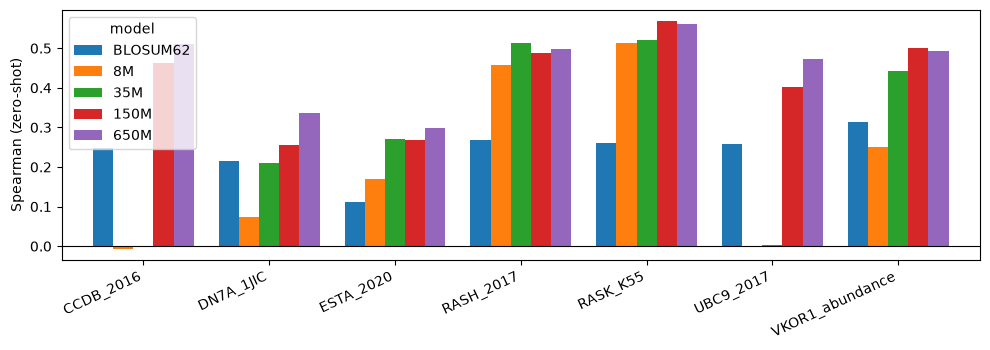

In [6]:
import matplotlib.pyplot as plt

piv = res.pivot(index="assay", columns="model", values="rho")[order]
fig, ax = plt.subplots(figsize=(10, 3.6))
piv.plot.bar(ax=ax, width=0.8)
ax.axhline(0, color="k", lw=0.8)
ax.set_ylabel("Spearman (zero-shot)")
ax.set_xlabel("")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

## 5. 비용이 싼 변형: wild-type marginal
마스크 없이 wt 서열을 한 번만 통과시킨다. forward가 L회에서 1회로 줄지만 wt 잔기가 입력에 보인다. 150M으로 차이를 본다.

In [7]:
tk150 = AutoTokenizer.from_pretrained(MODELS["150M"])
m150 = EsmForMaskedLM.from_pretrained(MODELS["150M"]).to(DEVICE).eval()
first_seq = next(iter(data.values()))[0]
masked_marginal_table(tk150, m150, first_seq); wt_marginal_table(tk150, m150, first_seq); sync()        # warm-up (첫 호출 오버헤드 제외)
rows = []
for a, (seq, df, typ) in data.items():
    t0 = time.time(); mtab = masked_marginal_table(tk150, m150, seq); sync(); t_masked = time.time() - t0
    t0 = time.time(); wtab = wt_marginal_table(tk150, m150, seq); sync(); t_wt = time.time() - t0
    rows.append(dict(assay=a.split("_")[0], masked=rho(score_variants(df, mtab), df.DMS_score.values),
                     wt_marginal=rho(score_variants(df, wtab), df.DMS_score.values), sec_masked=t_masked, sec_wt=t_wt))
cmp = pd.DataFrame(rows).set_index("assay")
print(cmp.round(3).to_string())
print("평균:", cmp.mean().round(3).to_dict())

Loading weights:   0%|          | 0/491 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 491/491 [00:00<00:00, 9456.65it/s]

       masked  wt_marginal  sec_masked  sec_wt
assay                                         
DN7A    0.255        0.288       0.469   0.032
ESTA    0.267        0.245       6.012   0.054
VKOR1   0.500        0.488       3.742   0.044
RASH    0.487        0.480       4.891   0.047
UBC9    0.403        0.390       3.534   0.047
CCDB    0.462        0.450       1.453   0.039
RASK    0.568        0.559       4.795   0.056
평균: {'masked': 0.42, 'wt_marginal': 0.414, 'sec_masked': 3.557, 'sec_wt': 0.046}


## 6. 해석 가이드
- **표준편차 대신 신뢰구간**: 같은 위치의 변이는 서로 상관되므로 변이 단위가 아니라 **위치 단위 부트스트랩**으로 구간을 구했다(모듈 01 5.4). 구간이 겹치면 순위가 뒤바뀔 수 있다.
- **assay 유형별로 본다**: 평균 하나로 모델을 줄 세우지 말고, 안정성·발현·활성·적합도·결합 각각에서 baseline(BLOSUM62) 대비 어떤지 본다.
- **크기 증가의 효과 (이 실행 기준, 직접 확인할 것)**
  - 7개 평균 Spearman(단순 평균이며 ProteinGym 공식 집계와 같지 않다)은 BLOSUM62 0.24, 8M 0.21, 35M 0.28, 150M 0.42, 650M 0.45다. 작은 모델(8M, 35M)은 평균적으로 BLOSUM62와 비슷한 수준이고 150M부터 크게 오른다.
  - **assay마다 다르다**: UBC9·CCDB(OrganismalFitness)는 8M·35M에서 상관이 0 근처이고 150M 이상에서 0.40~0.51로 오른다. RASH·RASK·VKOR1은 8M에서도 0.25~0.51로 이미 높고 크기 증가 효과가 작다.
  - **이 두 안정성 assay(DN7A, ESTA)에서는 모든 크기에서 낮은 편**(0.07~0.34)이며, DN7A에서는 BLOSUM62 [0.13, 0.31]과 650M [0.20, 0.49]의 신뢰구간이 겹친다.
    이것을 안정성 assay 전반의 성질로 일반화하면 안 된다. 선택한 두 assay의 결과일 뿐이며, 유형별 전체 경향은 ProteinGym 공식 점수표에서 확인한다†.
  - **단조롭지 않다**: 150M에서 650M으로 갈 때 RASH(0.49에서 0.50), RASK(0.57에서 0.56), VKOR1(0.50에서 0.49)은 사실상 같거나 약간 낮고 구간이 겹친다.
- **wt marginal vs masked marginal (150M)**: 평균이 0.414 대 0.420으로 거의 같고 assay별로도 차이가 작다(DN7A는 wt marginal이 0.288로 약간 높음). forward가 L회에서 1회로 줄어 시간은 크게 다르다. 이 실행(150M, 워밍업 후 동기화 측정)에서 assay당 평균 masked 약 3.6초 vs wt 약 0.05초로 약 70배 차이였다(5절 표의 `sec_*` 열).
  다만 7개 assay와 150M 하나의 결과이며, wt marginal은 정답 잔기를 입력에 그대로 보여 주므로 모델 크기·체크포인트에 따라 분포가 달라질 수 있다. 일반화하지 말고 대상 모델에서 따로 확인한다.
- **ProteinGym 전체 평균과 직접 비교하지 않는다**: 여기서는 7개 assay와 단일 치환만 썼다. 공식 순위는 ProteinGym 점수표를 참고한다.

## 7. 한계와 주의
- 단일 치환 전용이다. 다중 치환에 쓰려면 위치별 점수를 합산하는 독립 가정(상위성 무시)이 필요하다.
- ESM-2는 사전학습에 DMS 대상 단백질 또는 그 상동체를 포함했을 수 있다 (사전학습–평가 겹침, 모듈 01 5.2).
- 점수는 "자연 서열 분포에서의 그럴듯함"의 대리 지표다. DMS 점수가 측정하는 기능(안정성, 활성, 결합 등)과의 일치는 assay마다 다르다.
- 과제: [../exercises.md](../exercises.md) 과제 2, 3.